<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/01_tabular/04_regression_app_house_prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏡 Application · Tabular regression: House Prices (the Kaggle classic)

In 2011, Professor **Dean De Cock** was tired of teaching regression with the old Boston Housing dataset. He went to
the assessor's office of **Ames, Iowa**, and assembled the sales of 2 930 homes from 2006 to 2010, each described by
**79 variables**: quality of the kitchen, size of the garage, type of roof, neighbourhood, presence of a pool…
Kaggle turned it into *"House Prices: Advanced Regression Techniques"*, one of the most played competitions ever.

**Mission:** predict `SalePrice` from the description of the house.
**Metric:** RMSE between the **logarithms** of the predicted and real prices (RMSLE). Being $20k off on a $100k house
is as bad as being $200k off on a $1M house.

**What's new compared to the California quest**
- 🧩 **many** features of every type (numeric, nominal, *ordinal*), with lots of missing values
- 🕳️ missing values that **mean something** ("no garage" is not "unknown garage")
- 📉 a log-transformed target to match the metric
- 🧮 regularised linear models (**Ridge, Lasso**) vs gradient boosting
- 🧹 outliers recommended for removal by the dataset's author himself
- 🤝 a blend, and a Kaggle-format submission

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "catboost"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
quest("House Prices", chapter="Track 1 · Tabular · Regression (application)", xp=300)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · House Prices
   Track 1 · Tabular · Regression (application)
   Reward: up to 300 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 1. Load 📥

OpenML hosts the 1 460 houses of Kaggle's training file. We keep 20% aside as a private test set to check our final
model honestly.

In [3]:
from sklearn.model_selection import train_test_split

df = openml(42165)
train, test = train_test_split(df, test_size=0.2, random_state=SEED)
print(train.shape, test.shape)
train.head()

(1168, 81) (292, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
254,255,20,RL,70.0,8400,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2010,WD,Normal,145000
1066,1067,60,RL,59.0,7837,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2009,WD,Normal,178000
638,639,30,RL,67.0,8777,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,5,2008,WD,Normal,85000
799,800,50,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,6,2007,WD,Normal,175000
380,381,50,RL,50.0,5000,Pave,Pave,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,127000


## 2. The target and the metric 🎯

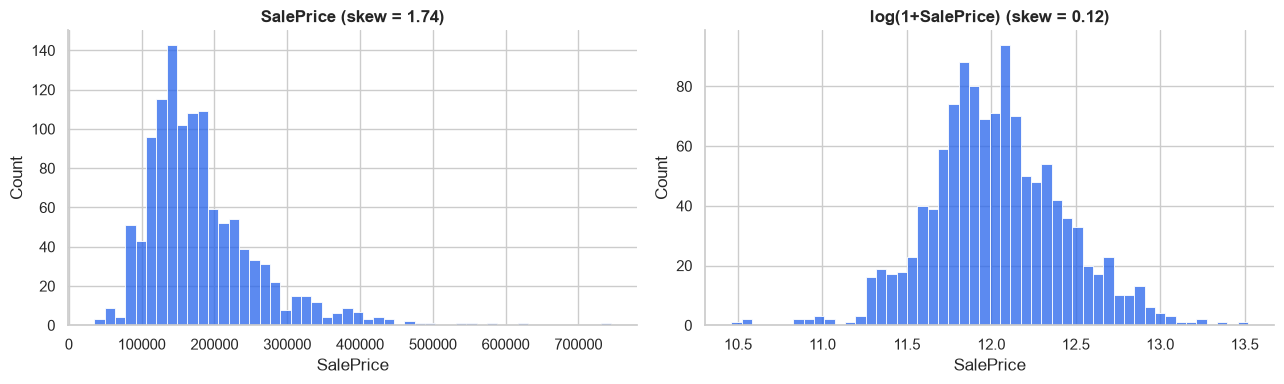

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(train["SalePrice"], bins=50, ax=axes[0]).set(title=f"SalePrice (skew = {train['SalePrice'].skew():.2f})")
sns.histplot(np.log1p(train["SalePrice"]), bins=50, ax=axes[1]).set(title=f"log(1+SalePrice) (skew = {np.log1p(train['SalePrice']).skew():.2f})")
plt.tight_layout(); plt.show()

The raw price is right-skewed; its log is nearly bell-shaped. Since the metric is computed on logs, we simply
**train on `log1p(SalePrice)`** and evaluate with a plain RMSE: that *is* the competition metric.

## 3. Outliers recommended by the author 🧹

De Cock's documentation says: *"there are 5 observations that an instructor may wish to remove… I would recommend
removing any houses with more than 4000 square feet."* Let's look.

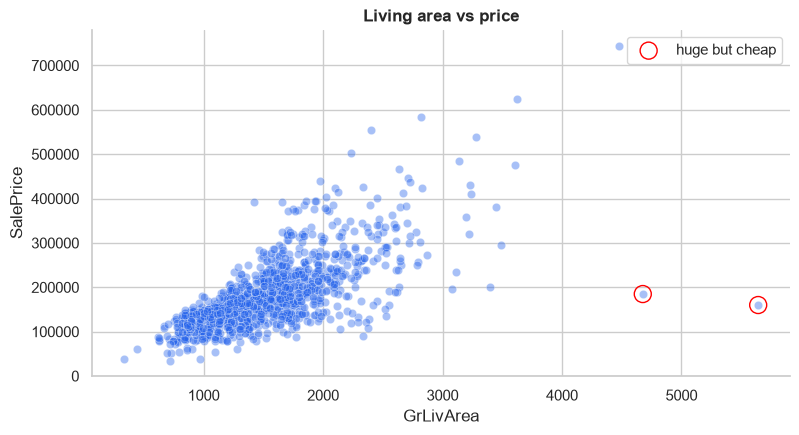

      GrLivArea  SalePrice SaleCondition
523        4676     184750       Partial
1298       5642     160000       Partial


In [5]:
ax = sns.scatterplot(data=train, x="GrLivArea", y="SalePrice", alpha=0.4)
big_cheap = train[(train["GrLivArea"] > 4000) & (train["SalePrice"] < 300_000)]
ax.scatter(big_cheap["GrLivArea"], big_cheap["SalePrice"], s=150, facecolors="none", edgecolors="red", label="huge but cheap")
ax.set(title="Living area vs price"); ax.legend(); plt.show()
print(big_cheap[["GrLivArea", "SalePrice", "SaleCondition"]])

Huge houses sold for almost nothing, with `SaleCondition = Partial` (unfinished). They would pull a linear model
towards absurd slopes. We remove them **from the training set only** (never from the test set: you can't delete
the houses you're asked to price!).

In [6]:
train = train.drop(big_cheap.index)
y, y_test = np.log1p(train.pop("SalePrice")), np.log1p(test.pop("SalePrice"))
train_ids, test_ids = train.pop("Id"), test.pop("Id")

## 4. Missing values that mean something 🕳️

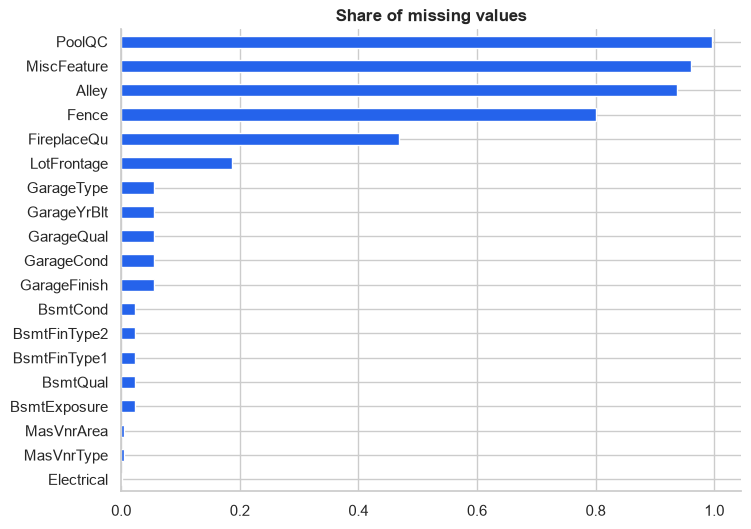

In [7]:
missing = train.isna().mean().sort_values(ascending=False)
missing[missing > 0].head(20).plot.barh(figsize=(8, 6), title="Share of missing values").invert_yaxis()
plt.show()

Read the data description: `PoolQC` is missing when there is **no pool**, `Alley` when there is **no alley**,
`GarageType` when there is **no garage**… These are not unknowns, they are a category of their own. So:

- for those columns: fill text with `"None"` and the matching areas/counts with `0`;
- `LotFrontage` (street length in front of the lot) is genuinely unknown: fill with the **median of the
  neighbourhood** (houses on the same street look alike);
- the few remaining gaps: most frequent value / median, inside the pipeline.

## 5. Feature engineering 🛠️

Three ideas that experienced competitors always try here:
1. **Ordinal encoding**: quality columns go `Po < Fa < TA < Gd < Ex` (poor → excellent). One-hot would lose the order;
   mapping them to 1…5 keeps it.
2. **Aggregates**: total surface, total bathrooms, age of the house when sold, years since renovation.
3. **Log of skewed areas** for the linear models.

In [8]:
NONE_MEANS_ABSENT = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu", "GarageType", "GarageFinish",
                     "GarageQual", "GarageCond", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
                     "BsmtFinType2", "MasVnrType"]
ZERO_MEANS_ABSENT = ["GarageYrBlt", "GarageArea", "GarageCars", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF",
                     "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath", "MasVnrArea"]
QUALITY = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ORDINAL_COLS = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual", "FireplaceQu",
                "GarageQual", "GarageCond", "PoolQC"]

lot_frontage_by_hood = train.groupby("Neighborhood")["LotFrontage"].median()   # learnt on train only!

def make_features(data: pd.DataFrame) -> pd.DataFrame:
    data = data.copy()
    data[NONE_MEANS_ABSENT] = data[NONE_MEANS_ABSENT].fillna("None")
    data[ZERO_MEANS_ABSENT] = data[ZERO_MEANS_ABSENT].fillna(0)
    data["LotFrontage"] = data["LotFrontage"].fillna(data["Neighborhood"].map(lot_frontage_by_hood))
    for col in ORDINAL_COLS:
        data[col + "_num"] = data[col].map(QUALITY).fillna(0)
    data["MSSubClass"] = data["MSSubClass"].astype(str)          # a code, not a quantity!
    data["TotalSF"] = data["TotalBsmtSF"] + data["1stFlrSF"] + data["2ndFlrSF"]
    data["TotalBath"] = data["FullBath"] + 0.5 * data["HalfBath"] + data["BsmtFullBath"] + 0.5 * data["BsmtHalfBath"]
    data["HouseAge"] = data["YrSold"] - data["YearBuilt"]
    data["YearsSinceRemod"] = data["YrSold"] - data["YearRemodAdd"]
    data["TotalPorchSF"] = data[["OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch", "WoodDeckSF"]].sum(axis=1)
    data["QualxSF"] = data["OverallQual"] * data["TotalSF"]
    data["HasPool"] = (data["PoolArea"] > 0).astype(int)
    data["HasGarage"] = (data["GarageArea"] > 0).astype(int)
    text_cols = data.select_dtypes(include=["object", "string"]).columns
    data[text_cols] = data[text_cols].fillna("Missing")          # CatBoost wants strings, not NaN
    return data

X, X_test = make_features(train), make_features(test)
cat_cols = X.select_dtypes(include=["object", "string"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print(f"{X.shape[1]} features: {len(num_cols)} numeric, {len(cat_cols)} categorical")

97 features: 53 numeric, 44 categorical


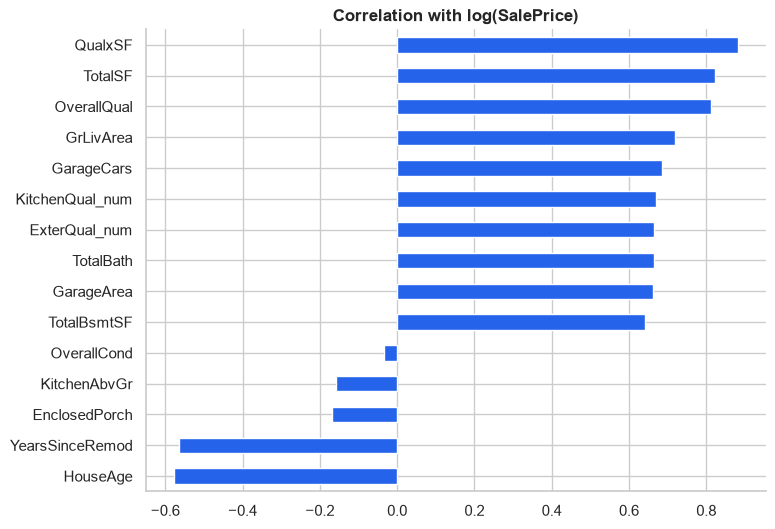

In [9]:
corr = X[num_cols].corrwith(y).sort_values()
pd.concat([corr.head(5), corr.tail(10)]).plot.barh(figsize=(8, 6), title="Correlation with log(SalePrice)")
plt.show()

Our engineered `QualxSF` and `TotalSF` beat every original column. Domain knowledge pays.

## 6. Models 🏗️

**Ridge** and **Lasso** are linear regressions with a penalty on large weights (*regularisation*): with 250+
one-hot columns and 1 160 houses, a plain linear regression would overfit wildly. Lasso can even set weights to
exactly zero (automatic feature selection, Tibshirani 1996).

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler, FunctionTransformer
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.ensemble import HistGradientBoostingRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
skewed = [c for c in num_cols if X[c].skew() > 1 and X[c].min() >= 0]

linear_prep = ColumnTransformer([
    ("skewed", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p), RobustScaler()), skewed),
    ("num", make_pipeline(SimpleImputer(strategy="median"), RobustScaler()), [c for c in num_cols if c not in skewed]),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore", min_frequency=5)), cat_cols),
])
tree_prep = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore", min_frequency=5)), cat_cols),
])

models = {
    "Ridge": lambda: make_pipeline(linear_prep, RidgeCV(alphas=np.logspace(-1, 3, 30))),
    "Lasso": lambda: make_pipeline(linear_prep, LassoCV(alphas=np.logspace(-4.5, -2, 30), max_iter=50_000, cv=5)),
    "HistGradientBoosting": lambda: make_pipeline(tree_prep, HistGradientBoostingRegressor(
        max_iter=1500, learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=10, l2_regularization=1.0, random_state=SEED)),
    "LightGBM": lambda: make_pipeline(tree_prep, LGBMRegressor(
        n_estimators=2000, learning_rate=0.01, num_leaves=12, min_child_samples=10, subsample=0.7, subsample_freq=1,
        colsample_bytree=0.4, reg_lambda=1.0, random_state=SEED, verbose=-1)),
    "CatBoost": lambda: CatBoostRegressor(iterations=2000, learning_rate=0.03, depth=5, l2_leaf_reg=3,
                                          cat_features=cat_cols, random_seed=SEED, verbose=0, allow_writing_files=False),
}


def run_cv(make_model):
    """Hand-written CV loop: out-of-fold predictions + RMSE per fold (log scale = the competition metric)."""
    oof_pred, scores = np.zeros(len(X)), []
    for tr, va in cv.split(X):
        model = make_model().fit(X.iloc[tr], y.iloc[tr])
        oof_pred[va] = model.predict(X.iloc[va])
        scores.append(np.sqrt(np.mean((y.iloc[va] - oof_pred[va]) ** 2)))
    return oof_pred, np.array(scores)


lb = Leaderboard("house_prices", metric="RMSLE", higher_is_better=False)
lb.add("Predict the mean", np.sqrt(np.mean((y - y.mean()) ** 2)))
oof = {}
for name, make_model in models.items():
    oof[name], scores = run_cv(make_model)
    lb.add(name, scores.mean(), std=round(scores.std(), 4))
lb.show()

📋 Predict the mean: RMSLE = 0.39076


📋 Ridge: RMSLE = 0.10772  👑 new best!


📋 Lasso: RMSLE = 0.10751  👑 new best!


📋 HistGradientBoosting: RMSLE = 0.11972


📋 LightGBM: RMSLE = 0.11135


📋 CatBoost: RMSLE = 0.11340


,,model,RMSLE,std
rank,,,,
1,🥇,Lasso,0.10751,0.0032
2,🥈,Ridge,0.10772,0.0027
3,🥉,LightGBM,0.11135,0.0034
4,,CatBoost,0.11340,0.0054
5,,HistGradientBoosting,0.11972,0.0036
6,,Predict the mean,0.39076,NaN


Look at the leaderboard: on this dataset, **well-regularised linear models compete with gradient boosting**. With
good features and the log target, the relationship is close to linear. Each family captures something different,
which is exactly what a blend needs.

In [11]:
checkpoint("houses/models", xp=80)

✅ Checkpoint · houses/models (+80 XP)
   ███████████████████░░░░░ 80/100 XP


## 7. Blend 🤝

Let's find blend weights on the out-of-fold predictions with a tiny optimisation (weights ≥ 0, summing to 1).
Fitting weights on OOF predictions is safe because no model saw those rows when predicting them.

In [12]:
from scipy.optimize import minimize

names = list(oof)
P = np.column_stack([oof[n] for n in names])
loss = lambda w: np.sqrt(np.mean((y.to_numpy() - P @ w) ** 2))
res = minimize(loss, x0=np.ones(len(names)) / len(names), bounds=[(0, 1)] * len(names),
               constraints={"type": "eq", "fun": lambda w: w.sum() - 1})
weights = pd.Series(res.x, index=names).round(3)
print(weights.to_string())
lb.add("Optimised blend", res.fun)
lb.add("Simple average", loss(np.ones(len(names)) / len(names)))
lb.show()

Ridge                   0.282
Lasso                   0.333
HistGradientBoosting    0.000
LightGBM                0.349
CatBoost                0.036
📋 Optimised blend: RMSLE = 0.10530  👑 new best!
📋 Simple average: RMSLE = 0.10673


,,model,RMSLE,std
rank,,,,
1,🥇,Optimised blend,0.10530,NaN
2,🥈,Simple average,0.10673,NaN
3,🥉,Lasso,0.10751,0.0032
4,,Ridge,0.10772,0.0027
5,,LightGBM,0.11135,0.0034
6,,CatBoost,0.11340,0.0054
7,,HistGradientBoosting,0.11972,0.0036
8,,Predict the mean,0.39076,NaN


⚠️ Optimised weights can overfit the OOF predictions a little. The simple average is a robust alternative; if the
two are close, prefer the simpler one.

## 8. Final check on the hidden houses and submission 📤

In [13]:
test_preds = {}
for name, make_model in models.items():
    test_preds[name] = make_model().fit(X, y).predict(X_test)
    print(f"{name:<22} test RMSLE = {np.sqrt(np.mean((y_test - test_preds[name]) ** 2)):.4f}")
blend_test = np.column_stack([test_preds[n] for n in names]) @ weights.to_numpy()
blend_rmsle = np.sqrt(np.mean((y_test - blend_test) ** 2))
print(f"{'Optimised blend':<22} test RMSLE = {blend_rmsle:.4f}   (CV said {res.fun:.4f})")

submission = pd.DataFrame({"Id": test_ids.to_numpy(), "SalePrice": np.expm1(blend_test).round(0)})
make_submission(submission, "house_prices_submission.csv")
submission.head()

Ridge                  test RMSLE = 0.1284


Lasso                  test RMSLE = 0.1246


HistGradientBoosting   test RMSLE = 0.1356


LightGBM               test RMSLE = 0.1287


CatBoost               test RMSLE = 0.1274
Optimised blend        test RMSLE = 0.1242   (CV said 0.1053)
📤 Submission saved: submissions/house_prices_submission.csv  (292 rows, columns=['Id', 'SalePrice'])


,Id,SalePrice
0,893,150054.0
1,1106,333256.0
2,414,102761.0
3,523,155908.0
4,1037,327002.0


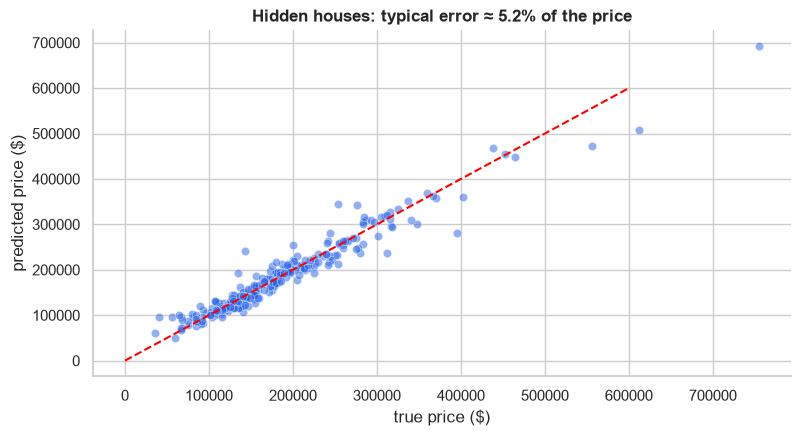

In [14]:
true_price = np.expm1(y_test)
pred_price = np.expm1(blend_test)
ax = sns.scatterplot(x=true_price, y=pred_price, alpha=0.5)
ax.plot([0, 6e5], [0, 6e5], "r--")
ax.set(xlabel="true price ($)", ylabel="predicted price ($)",
       title=f"Hidden houses: typical error ≈ {np.median(np.abs(pred_price / true_price - 1)):.1%} of the price")
plt.show()

**Why is the test score worse than the CV score?** Two honest reasons. First, 292 houses is a small sample: one or two
very unusual houses move the RMSLE a lot (look at the points far from the red line). Second, we removed the weirdest
houses from *training* but, rightly, kept every house in the test set. This gap between local and leaderboard scores
is normal; what matters is that **the ranking of models stays consistent**, and here the blend is best in both.

## 🏁 Mission accomplished

You handled 79 messy features, encoded domain knowledge (meaningful missing values, ordinal qualities), matched the
training target to the metric, compared regularised linear models with boosters and blended them.

### 🚀 Your turn
1. **Neighbourhood price level:** add the median log-price per neighbourhood as a feature. ⚠️ It uses the target:
   compute it **inside each training fold** (target encoding), or you'll leak. Does CV improve?
2. **More outliers?** Look at the largest out-of-fold errors (`y - oof["Lasso"]`). Are they data errors?
3. **Try an SVR or kernel ridge** on `linear_prep`: these were part of many top-10% solutions.
4. **Go compete:** Kaggle's [House Prices](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques)
   competition is always open. Same columns, so this notebook is almost a ready-made submission.

In [15]:
checkpoint("houses/complete", xp=220)
badge("Ames Appraiser", "🏡")
progress()

✅ Checkpoint · houses/complete (+220 XP)
🎉 LEVEL UP! You are now 🧭 Feature Pathfinder
   ░░░░░░░░░░░░░░░░░░░░░░░░ 300/600 XP
╔═══════════════════════════════════╗
║ 🏡  BADGE UNLOCKED: Ames Appraiser ║
╚═══════════════════════════════════╝
🧭 Feature Pathfinder
░░░░░░░░░░░░░░░░░░░░░░░░ 300/600 XP
Checkpoints unlocked: 2
Badges: 🏡 Ames Appraiser
